# Exploratory Data Analysis of Global Reserve and Ore Distribution

Di mana saja cadangan bijih dunia berada? Komoditas apa yang paling banyak situsnya?

Pada Notebook ini saya akan mengeksplorasi basis data **sebaran ore global** — ratusan ribu titik lokasi tambang/deposit di seluruh dunia — lalu melengkapinya dengan data **cadangan batubara per negara**.

> 🎯 **Tujuan Pembelajaran**
> - Mengambil **sampel** dari dataset besar (ratusan ribu baris) agar ringan.
> - Menghitung peringkat negara & komoditas dengan `value_counts`.
> - Membuat **scatter geografis** (longitude vs latitude) sebagai peta sederhana.
> - Menggabungkan dua dataset untuk sudut pandang lebih kaya (ore + batubara).

## About the Dataset

**1) Mineral Ores Around the World** — titik-titik lokasi deposit/tambang bijih global.

- **Sumber:** [Kaggle — ramjasmaurya/mineral-ores-around-the-world](https://www.kaggle.com/datasets/ramjasmaurya/mineral-ores-around-the-world)
- **Ukuran asli:** 304.632 baris × 22 kolom → kita **ambil sampel 50.000 baris** (`random_state=42`) agar ringan.

| Kolom | Arti |
|-------|------|
| `country` | Negara lokasi deposit |
| `commod1` | Komoditas utama (mis. Gold, Copper, Iron) |
| `com_type` | Tipe komoditas |
| `dep_type` | Tipe deposit |
| `oper_type` | Tipe operasi |
| `latitude`, `longitude` | Koordinat geografis |

**2) Coal Reserves by Type** — cadangan batubara per negara (pelengkap).

- **Sumber:** [Kaggle — valchovalev/coalreservesbytype](https://www.kaggle.com/datasets/valchovalev/coalreservesbytype) — 47 baris × 5 kolom

## Import Library

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Import The Dataset

In [2]:
!pip install kaggle
!mkdir ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json
!kaggle datasets download -d ramjasmaurya/mineral-ores-around-the-world
!unzip mineral-ores-around-the-world.zip

cp: cannot stat 'kaggle.json': No such file or directory
chmod: cannot access '/root/.kaggle/kaggle.json': No such file or directory
Dataset URL: https://www.kaggle.com/datasets/ramjasmaurya/mineral-ores-around-the-world
License(s): CC0-1.0
100% 8.65M/8.65M [00:00<00:00, 11.0MB/s]

Archive:  mineral-ores-around-the-world.zip
  inflating: Mineral ores round the world.csv  


In [24]:
!kaggle datasets download -d valchovalev/coalreservesbytype
!unzip coalreservesbytype.zip

Dataset URL: https://www.kaggle.com/datasets/valchovalev/coalreservesbytype
License(s): unknown
100% 1.01k/1.01k [00:00<00:00, 2.84MB/s]

Archive:  coalreservesbytype.zip
  inflating: coal-reserves-by-type.csv  


##Initial Exploration

In [13]:
df = pd.read_csv('/content/Mineral ores round the world.csv')
df.head()

/tmp/ipykernel_8177/748459933.py:1: DtypeWarning: Columns (13,19) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('/content/Mineral ores round the world.csv')


,site_name,latitude,longitude,region,country,state,county,com_type,commod1,commod2,...,dep_type,prod_size,dev_stat,ore,gangue,work_type,names,ore_ctrl,hrock_type,arock_type
0,Lookout Prospect,55.05612,-132.14344,NaN,United States,Alaska,NaN,M,Copper,"Gold, Silver",...,NaN,N,Occurrence,"Chalcopyrite, Covellite, Pyrite","Quartz, Sericite",NaN,"Conundrum, Mammoth, Wakefield Minerals Co.",NaN,Schist,NaN
1,Lucky Find Prospect,55.52751,-132.68514,NaN,United States,Alaska,NaN,M,Copper,Gold,...,NaN,N,Occurrence,"Chalcopyrite, Pyrite","Calcite, Quartz, Siderite",Underground,NaN,Vein Follows Contact,Diabase,NaN
2,Mccullough Prospect,55.97751,-132.99906,NaN,United States,Alaska,NaN,M,Copper,NaN,...,NaN,N,Occurrence,"Chalcopyrite, Pyrite, Sphalerite",Quartz,NaN,"Claims: Horseshoe, Copper, Lake Bay",NaN,Siltstone,NaN
3,Lucky Jim Claim,55.52195,-132.68653,NaN,United States,Alaska,NaN,M,Gold,NaN,...,NaN,N,Occurrence,"Galena, Malachite, Pyrite",NaN,NaN,NaN,NaN,Granite,Granite
4,Matilda Occurrence,55.14556,-132.05233,NaN,United States,Alaska,NaN,M,Gold,NaN,...,NaN,N,Occurrence,Pyrite,NaN,NaN,NaN,NaN,Mica Schist,NaN


In [14]:
df.shape

(304632, 22)

In [6]:
# Dataset ORES besar (304 ribu baris) -> ambil sampel 50.000 agar ringan (tetap data nyata)
df_ore = df.sample(n=50000, random_state=42)
df_ore.head()

,site_name,latitude,longitude,region,country,state,county,com_type,commod1,commod2,...,dep_type,prod_size,dev_stat,ore,gangue,work_type,names,ore_ctrl,hrock_type,arock_type
877,Mountain Boy Prospect,61.66021,-144.02781,NaN,United States,Alaska,NaN,M,Copper,Gold,...,NaN,N,Occurrence,"Bornite, Chalcocite, Chalcopyrite",NaN,NaN,Montana Boy,NaN,Greenstone,Greenstone
189495,Unnamed Prospect,34.79281,-117.57059,NaN,United States,California,San Bernardino,M,Copper,NaN,...,NaN,NaN,Prospect,NaN,NaN,NaN,NaN,NaN,NaN,NaN
239554,Accident,47.22132,-109.16079,NaN,United States,Montana,Fergus,M,Lead,NaN,...,NaN,NaN,Past Producer,NaN,NaN,NaN,"Greshchuk Claims, Golden Eagle Claims, Old Murphy",NaN,NaN,NaN
214286,Northside Mining Co. Mine,37.10147,-94.55803,NaN,United States,Missouri,Jasper,M,"Zinc, Lead",NaN,...,NaN,NaN,Past Producer,NaN,NaN,NaN,NaN,NaN,NaN,NaN
161369,Gravel Pit,37.56142,-105.99139,NaN,United States,Colorado,Alamosa,N,"Sand and Gravel, Construction",NaN,...,NaN,NaN,Past Producer,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [15]:
col_key = ["country", "commod1", "com_type", "dep_type", "oper_type", "latitude", "longitude"]
col_key = [k for k in col_key if k in df_ore.columns]
print(col_key)

df_ore[col_key].isnull().mean().mul(100).round(2)

['country', 'commod1', 'com_type', 'dep_type', 'oper_type', 'latitude', 'longitude']


,0
country,0.00
commod1,6.74
com_type,1.26
dep_type,87.87
oper_type,0.00
latitude,0.00
longitude,0.00


**Interpretation:**

Semua 7 kolom kunci ada, dan ini artinya secara singkat:

* **0% kosong (`country`, `oper_type`, `latitude`, `longitude`):** Data lengkap, aman langsung dipakai untuk peta dan ringkasan wilayah/operasi.
* **Kosong sedikit (`com_type` 1,26%, `commod1` 6,74%):** Cukup lengkap, tinggal sesuaikan filter baris yang kosong saat analisis komoditas.
* **Kosong sangat banyak (`dep_type` 87,87%):** Hampir 9 dari 10 baris kosong; hanya ~12,13% data yang terisi, jadi sebaiknya tidak dijadikan syarat wajib atau fitur utama tanpa pertimbangan.

## Exploratory Data Analysis & Visualization

### a)Countries with the most ore sites (top 10 bar chart)

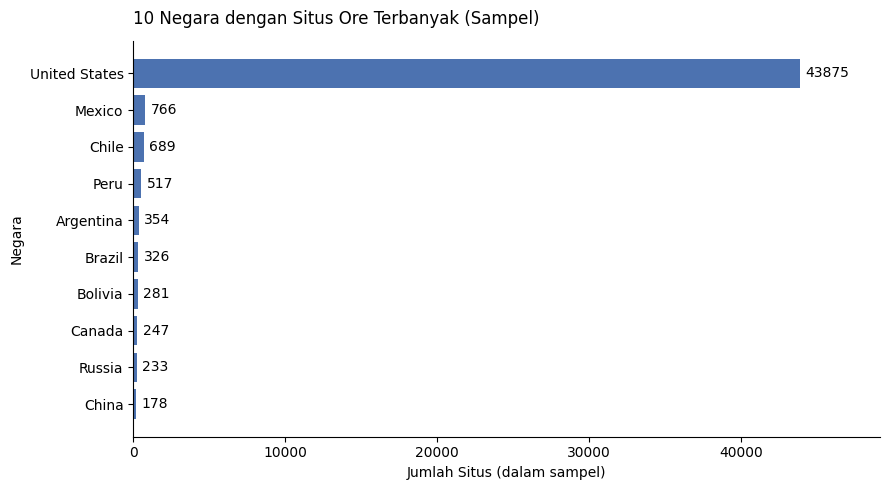

In [16]:
top_negara = (
    df_ore["country"]
    .dropna()
    .value_counts()
    .head(10)
    .sort_values(ascending=True)
)

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.barh(top_negara.index, top_negara.values, color="#4C72B0")

ax.set_title("10 Negara dengan Situs Ore Terbanyak (Sampel)", loc="left", pad=12)
ax.set_xlabel("Jumlah Situs (dalam sampel)")
ax.set_ylabel("Negara")
ax.bar_label(bars, fmt="%d", padding=4)
ax.set_xlim(0, top_negara.max() * 1.12)

ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

**Interpretation:**

Grafik ini memperlihatkan bahwa **United States** mendominasi jauh dibanding negara lain dalam dataset sampel ini:

* **Ketimpangan sangat besar:**
  - United States memiliki **43.875** situs, sementara posisi kedua (**Mexico**) hanya **766** situs—lebih dari 50 kali lipat perbedaannya.


* **Peringkat 2–10 berdekatan:**
  - Negara-negara setelah United States berada di rentang ratusan situs, mulai dari Mexico (**766**), Chile (**689**), dan Peru (**517**) hingga China (**178**).


* **Dominasi Amerika:**
  - Sebagian besar negara di daftar ini berasal dari benua Amerika (United States, Mexico, Chile, Peru, Argentina, Brazil, Bolivia, Canada), ditambah Russia dan China.



**Catatan penting:**
  - Karena judulnya mencantumkan kata *(Sampel)*, angka ini mencerminkan cakupan data yang ada di dataset `ores`—bukan berarti negara lain tidak punya situs tambang, melainkan bisa dipengaruhi oleh sumber atau kelengkapan data.

### b) Most frequent primary commodities (top-10 bar)

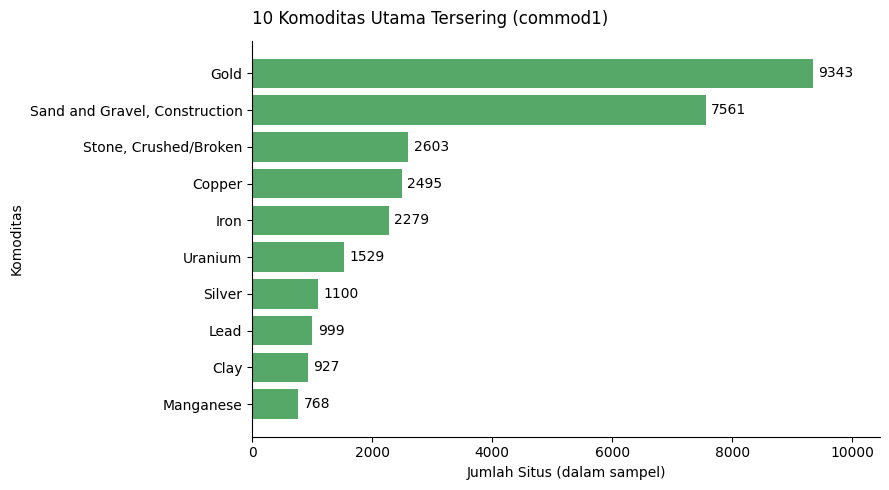

In [17]:
top_komod = (
    df_ore["commod1"]
    .dropna()
    .value_counts()
    .head(10)
    .sort_values(ascending=True)
)

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.barh(top_komod.index, top_komod.values, color="#55A868")

ax.set_title("10 Komoditas Utama Tersering (commod1)", loc="left", pad=12)
ax.set_xlabel("Jumlah Situs (dalam sampel)")
ax.set_ylabel("Komoditas")
ax.bar_label(bars, fmt="%d", padding=4)
ax.set_xlim(0, top_komod.max() * 1.12)

ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

**Interpretation:**


Grafik ini menunjukkan bahwa **Gold (emas)** dan **Sand and Gravel, Construction (pasir & kerikil konstruksi)** adalah dua komoditas utama yang paling banyak tercatat dalam sampel dataset ini:

* **Dua besar mendominasi:**
  - **Gold** berada di peringkat pertama dengan **9.343** situs, disusul **Sand and Gravel, Construction** dengan **7.561** situs. Keduanya terpaut sangat jauh dibanding peringkat ketiga.

* **Kelompok menengah (~2.200–2.600 situs):**
  - Di bawah dua teratas ada **Stone, Crushed/Broken** (2.603), **Copper** (2.495), dan **Iron** (2.279) dengan jumlah situs yang saling berdekatan.

* **Peringkat 6–10 menurun bertahap:**
  - Mulai dari **Uranium** (1.529), **Silver** (1.100), **Lead** (999), **Clay** (927), hingga **Manganese** (768).

* **Campuran logam & material konstruksi:**
  - Komoditas teratas tidak hanya didominasi logam berharga/industri (emas, tembaga, besi, perak, timbal), tetapi juga material non-logam untuk konstruksi seperti pasir, kerikil, batu pecah, dan lempung (*clay*).



Secara keseluruhan, dataset ini sangat banyak merekam lokasi pertambangan emas serta bahan galian konstruksi dasar.


### c) Geographic distribution map (scatter plot of longitude vs. latitude)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.5/9.5 MB 45.7 MB/s  0:00:00


/usr/local/lib/python3.13/dist-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/110m_physical/ne_110m_land.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)
/usr/local/lib/python3.13/dist-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/110m_physical/ne_110m_coastline.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)
/usr/local/lib/python3.13/dist-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/110m_cultural/ne_110m_admin_0_boundary_lines_land.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)


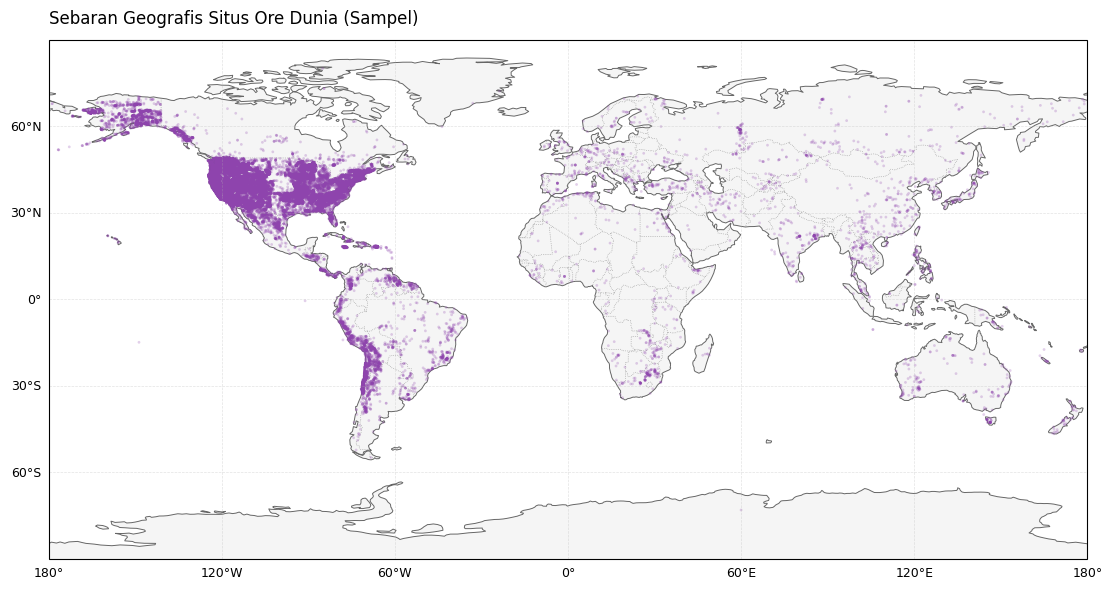

In [22]:
!pip install cartopy
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.pyplot as plt

geo = df_ore.dropna(subset=["latitude", "longitude"]).copy()
geo = geo[
    geo["latitude"].between(-90, 90) & geo["longitude"].between(-180, 180)
]

fig, ax = plt.subplots(
    figsize=(12, 6), subplot_kw={"projection": ccrs.PlateCarree()}
)

# Garis batas benua/pesisir dan batas negara
ax.add_feature(
    cfeature.LAND, facecolor="#F5F5F5", edgecolor="none", zorder=0
)
ax.add_feature(
    cfeature.COASTLINE, linewidth=0.7, edgecolor="#666666", zorder=1
)
ax.add_feature(
    cfeature.BORDERS,
    linewidth=0.5,
    linestyle=":",
    edgecolor="#999999",
    zorder=1,
)

# Plot titik situs ore di atas peta
ax.scatter(
    geo["longitude"],
    geo["latitude"],
    s=4,
    alpha=0.25,
    color="#8E44AD",
    edgecolors="none",
    transform=ccrs.PlateCarree(),
    zorder=2,
)

ax.set_extent([-180, 180, -90, 90], crs=ccrs.PlateCarree())
ax.set_title(
    "Sebaran Geografis Situs Ore Dunia (Sampel)", loc="left", pad=12
)

gl = ax.gridlines(
    draw_labels=True, linewidth=0.5, linestyle="--", alpha=0.35
)
gl.top_labels = False
gl.right_labels = False
gl.xlabel_style = {"size": 9}
gl.ylabel_style = {"size": 9}

fig.tight_layout()
plt.show()

**Interpretation:**

Peta ini menunjukkan bahwa titik situs *ore* tersebar di hampir semua benua berpenghuni, tetapi **kepadatannya sangat terkonsentrasi di wilayah tertentu**:

* **Klaster paling padat di Amerika Utara:**
  - Kepadatan ungu paling pekat terlihat di Amerika Serikat (termasuk wilayah barat, tengah, timur, serta Alaska) dan meluas ke Meksiko. Ini sejalan dengan grafik negara sebelumnya yang menunjukkan Amerika Serikat mendominasi jumlah situs.


* **Jalur memanjang di Amerika Selatan:**
  - Titik-titik banyak berderet mengikuti sisi barat Amerika Selatan (sepanjang pegunungan Andes, seperti Chile dan Peru) serta menyebar di sebagian Brasil.


* **Sebaran lebih merata & sporadis di wilayah lain:**
  - Di Eropa, Afrika, Asia (termasuk Asia Tenggara/Indonesia), dan Australia, titik-titik tetap ada dan membentuk beberapa kantong kecil, namun jauh lebih jarang dibanding Amerika Serikat.


* **Akurasi koordinat terjaga:**
  - Hampir seluruh titik berada tepat di atas daratan sesuai garis pantai dan batas negara, tanpa banyak titik liar di tengah laut atau di Antartika.



**Catatan konteks:**
  - Pola yang sangat padat di Amerika Utara juga bisa mencerminkan **cakupan sumber data** pada dataset sampel ini, selain faktor geologi dan aktivitas pertambangan.

## Supplementary Material: Coal Reserves by Country (COAL)

In [27]:
df_coal = pd.read_csv('/content/coal-reserves-by-type.csv')
df_coal.head()

,Entity,Code,Year,Coal - Reserves - Anthracite and bituminous,Coal - Reserves - Sub-bituminous and lignite
0,Asia Pacific,NaN,2019,342376000000,114437000000
1,Australia,AUS,2019,72571000000,76508000000
2,Brazil,BRA,2019,1547000000,5049000000
3,Bulgaria,BGR,2019,192000000,2174000000
4,CIS,NaN,2019,100208000000,90447000000


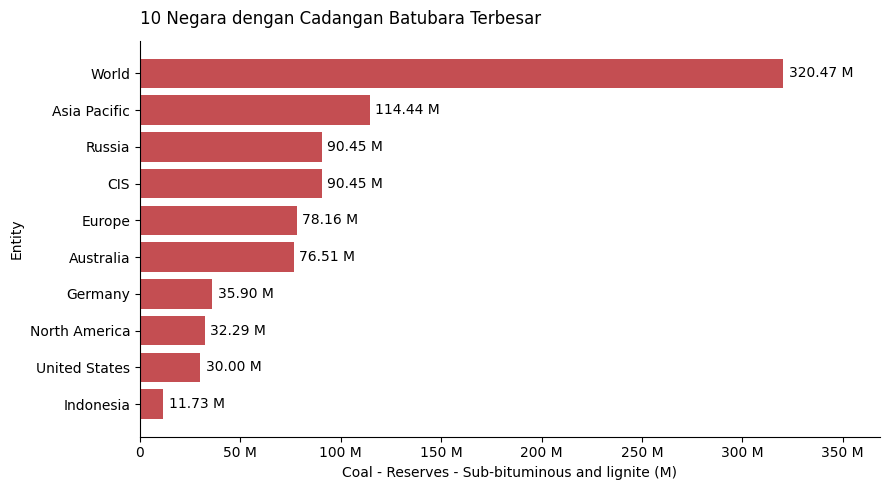

In [40]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

kol_num = df_coal.select_dtypes(include="number").columns
kol_label = df_coal.columns[0]

if len(kol_num) > 0 and not df_coal.empty:
    target_col = kol_num[-1]

    top_coal = (
        df_coal[[kol_label, target_col]]
        .dropna(subset=[kol_label, target_col])
        .set_index(kol_label)[target_col]
        .sort_values(ascending=False)
        .head(10)
        .sort_values(ascending=True)
    )

    # M = Miliar (dibagi 1e9)
    ke_m = lambda x, pos: f"{x / 1e9:g} M" if x != 0 else "0"
    label_batang = [f"{v / 1e9:.2f} M" for v in top_coal.values]

    fig, ax = plt.subplots(figsize=(9, 5))
    bars = ax.barh(top_coal.index.astype(str), top_coal.values, color="#C44E52")

    ax.set_title("10 Negara dengan Cadangan Batubara Terbesar", loc="left", pad=12)
    ax.set_xlabel(f"{target_col} (M)")
    ax.set_ylabel(str(kol_label))
    ax.xaxis.set_major_formatter(FuncFormatter(ke_m))
    ax.bar_label(bars, labels=label_batang, padding=4)
    ax.set_xlim(0, top_coal.max() * 1.15)

    ax.spines[["top", "right"]].set_visible(False)
    fig.tight_layout()
    plt.show()
else:
    print("Tidak ada kolom numerik yang tersedia atau coal kosong.")

**Interpretation:**

Grafik horizontal ini memvisualisasikan peringkat 10 entitas teratas untuk **cadangan batubara jenis *Sub-bituminous and lignite*** dalam satuan **`M`** (miliar). Berikut poin-poin interpretasi utamanya:

* **Posisi puncak & dominasi regional:**
  - **World** berada di urutan teratas dengan **320.47 M**, diikuti oleh kawasan **Asia Pacific** sebesar **114.44 M** (sekitar 35,7% dari total global pada grafik ini).


* **Negara tunggal terbesar:**
  - Jika menyaring entitas negara saja, **Russia** memimpin dengan **90.45 M**—nilai yang identik dengan blok **CIS** (**90.45 M**). Setelahnya terdapat **Australia** (**76.51 M**), **Germany** (**35.90 M**), **United States** (**30.00 M**), dan **Indonesia** di posisi ke-10 dengan **11.73 M**.


* **Kesenjangan antarperingkat:**
  - Terlihat lompatan cukup lebar dari posisi teratas (`World`) ke kawasan `Asia Pacific`, lalu menurun bertahap melalui kelompok `90 M – 76 M` (`Russia`, `CIS`, `Europe`, `Australia`) sebelum turun tajam ke kelompok `35 M – 11 M` (`Germany`, `North America`, `United States`, `Indonesia`).


* **Catatan kualitas data:**
  - Kolom `Entity` masih mencampur **agregat wilayah/dunia** (`World`, `Asia Pacific`, `CIS`, `Europe`, `North America`) dengan **negara individu**, sehingga judul *"10 Negara..."* belum sepenuhnya merepresentasikan 10 negara tunggal.





## Conclusions & Insights

Berdasarkan eksplorasi data yang telah dilakukan terhadap dataset **Mineral Ores Around the World** (sampel 50.000 baris) dan **Coal Reserves by Type**, berikut adalah kesimpulan dan insight utama yang dapat diambil:

1. Dominasi Data Geografis Amerika Serikat
    - **Fakta:**
      - United States (Amerika Serikat) mendominasi secara mutlak dengan **43.875 situs** dari total 50.000 sampel data (~87.7%). Posisi kedua diduduki oleh Meksiko dengan hanya 766 situs.
    - **Insight:**
      - Ketimpangan ekstrem ini menunjukkan adanya bias cakupan data (*data coverage bias*). Sangat mungkin dataset ini bersumber dari lembaga survei geologi AS (seperti USGS) yang mencatat wilayah domestik mereka dengan sangat detail dibandingkan belahan dunia lainnya. Oleh karena itu, peta sebaran yang sangat padat di Amerika Utara mencerminkan kelengkapan pencatatan, bukan berarti benua lain tidak memiliki cadangan mineral.

2. Emas dan Material Konstruksi sebagai Komoditas Terpopuler
    - **Fakta:** **Gold (Emas)**
      - menjadi komoditas utama yang paling sering dicatat (**9.343 situs**), diikuti oleh **Sand and Gravel, Construction** (**7.561 situs**).
    - **Insight:**
      - Tingginya pencatatan situs emas menunjukkan nilai ekonomi komoditas ini yang mendorong eksplorasi aktif secara global. Di sisi lain, material konstruksi (pasir, kerikil, batu pecah) menempati porsi besar karena merupakan kebutuhan dasar pembangunan infrastruktur lokal yang tersebar luas di hampir setiap wilayah aktif.

3. Distribusi Cadangan Batubara Dunia
    - **Fakta:**
      - Untuk cadangan batubara tipe *Sub-bituminous and lignite*, kawasan **Asia Pasifik** memimpin secara regional dengan **114.44 Miliar Ton** (~35.7% global). Di tingkat negara individu, **Rusia** memimpin dengan **90.45 Miliar Ton**, disusul Australia (76.51 M), Jerman (35.90 M), Amerika Serikat (30.00 M), dan **Indonesia** di posisi ke-10 dengan **11.73 Miliar Ton**.
    - **Insight:**
      - Asia Pasifik dan Rusia memegang peran kunci strategis dalam ketahanan energi batubara dunia. Meskipun dunia sedang bertransisi menuju energi terbarukan, cadangan batubara yang masif di wilayah ini masih memengaruhi lanskap geopolitik energi global secara signifikan.
